<a href="https://colab.research.google.com/github/xindra311-jpg/KoasianBot/blob/main/Sentiment_Analysis_Warkop_DKI_Lagi_dengan_Naive_Bayes_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import re
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import classification_report
import nltk
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
nltk.download('punkt')
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.pipeline import Pipeline
from wordcloud import WordCloud, STOPWORDS
from transformers import pipeline
import Sastrawi
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory, StopWordRemover, ArrayDictionary
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.naive_bayes import MultinomialNB

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


1 Cleaning Data

In [6]:
df = pd.read_csv("data/data.csv")
df.head ()

,page,name,link,thumbnail,rating,date,snippet,images,local_guide
0,1,Mirna Dewi,https://www.google.com/maps/contrib/1150471763...,https://lh3.googleusercontent.com/a-/ALV-UjVpE...,1.0,8 bulan lalu,Niatt pengen bgt nasi ronda nya karna dulu buk...,['https://lh3.googleusercontent.com/grass-cs/A...,True
1,1,Pendaki Malas,https://www.google.com/maps/contrib/1021176152...,https://lh3.googleusercontent.com/a-/ALV-UjUrm...,5.0,2 bulan lalu,"pancongnya enak, pesen kering aja/sangat matan...",['https://lh3.googleusercontent.com/grass-cs/A...,True
2,1,Bella Renata,https://www.google.com/maps/contrib/1036569896...,https://lh3.googleusercontent.com/a-/ALV-UjWhl...,4.0,11 bulan lalu,"Overall enak dan nyaman, malem2 laper dan ping...",['https://lh3.googleusercontent.com/grass-cs/A...,True
3,1,fif rima,https://www.google.com/maps/contrib/1120542997...,https://lh3.googleusercontent.com/a/ACg8ocLRQ6...,5.0,7 bulan lalu,"Tempatnya nyaman,untuk makanannya the best apa...",['https://lh3.googleusercontent.com/grass-cs/A...,True
4,1,Neilla Avanty,https://www.google.com/maps/contrib/1148895209...,https://lh3.googleusercontent.com/a-/ALV-UjWz3...,5.0,5 bulan lalu,"Makanan enak semua, snack juga enak, pegawai r...",['https://lh3.googleusercontent.com/grass-cs/A...,True


In [7]:
df = df[['snippet', 'rating']]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 578 entries, 0 to 577
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   snippet  578 non-null    object 
 1   rating   578 non-null    float64
dtypes: float64(1), object(1)
memory usage: 9.2+ KB


In [8]:
df['snippet'] = df['snippet'].astype(str).str.lower()  # Mengubah teks menjadi lowercase
df['snippet'] = df['snippet'].replace('false', pd.NA)  # Mengganti 'false' dengan pd.NA (Not Available)
df = df.dropna(subset=['snippet'])
df = df[df['snippet'] != 'false']

In [9]:
df = df.drop_duplicates(subset=['snippet'])

In [10]:
df = df.dropna()

In [11]:
def clean_gmaps_text(text):
  text = re.sub(r'@[A-Za-z0-9_]+', '', text)
  text = re.sub(r'#\w+', '', text)
  text = re.sub(r'RT[\s]+', '', text)
  text = re.sub(r'https?://\S+', '', text)

  text = re.sub(r'[^A-Za-z0-9 ]', '', text)
  text = re.sub(r'\s+', ' ', text).strip()

  return text

df['snippet'] = df['snippet'].apply(clean_gmaps_text)

In [12]:
df.head()

,snippet,rating
0,niatt pengen bgt nasi ronda nya karna dulu buk...,1.0
1,pancongnya enak pesen kering ajasangat matang ...,5.0
2,overall enak dan nyaman malem2 laper dan pingi...,4.0
3,tempatnya nyamanuntuk makanannya the best apa ...,5.0
4,makanan enak semua snack juga enak pegawai ram...,5.0


2. preprocecing

Filter Token

In [14]:
# Definisi fungsi filter_tokens_by_length
def filter_tokens_by_length(dataframe, column, min_words, max_words):
    # Tokenisasi kata
    words_count = dataframe[column].astype(str).apply(lambda x: len(x.split()))
    # Membuat filter untuk jumlah kata
    mask = (words_count >= min_words) & (words_count <= max_words)
    # Mengaplikasikan filter ke DataFrame
    filtered_df = dataframe[mask]
    return filtered_df

# Menggunakan filter_tokens_by_length untuk mendapatkan baris dengan jumlah kata antara 3 dan 50
min_words = 3
max_words = 50
df = filter_tokens_by_length(df, 'review', min_words, max_words)

Normalisasi

In [15]:
# Normalisasi
norm = {' bpk ':' bapak ', ' lg ':' lagi ', 'kyk ':'kayak ',' mkan ':' makan ', ' bljr ':' belajar ',' tak ':' tidak ', ' dpt ':' dapat ', ' gt ':' gitu ', ' rebu ':' ribu ',' skrg ':' sekarang ', ' trs ':' terus ', 'lu ':'kamu ', ' sj ':' saja ', ' jg ':' juga ', ' ga ':' tidak ', ' tsb ':' tersebut ', ' sibangsat ':' bangsat ',' yg ':' yang ', ' udh ':' udah ', 'wkwk ':' ', ' min ':' kak ', ' malem ':' malam', ' malem2 ':' malam ', ' sm ':' sama ', ' dy ':' dia ', ' lg ':' lagi ', ' skrg ':' sekarang ', ' ddpn ':' didepan ', ' makasi ':' makasih ', ' pertamaz ':' pertamax ', ' jg ':' juga ', ' donk ':' dong ', ' ikutann ':' ikutan ', ' banyakk ':' banyak ', ' twt ':' tweet', 'mantaap ':'mantap ', ' juarak':' juara ', 'daridulu ':'dari dulu ', 'siapp ':'siap ', ' gamau ':' tidak mau ', ' sll ':' selalu ', ' qu ':' aku ', ' krn ':' karena ', ' irii':' iri', ' muluu ':' terus ', 'mada ':'masa ', 'jgn ':'jangan ', ' jgn ':' jangan ', ' muluuu ':' terus ', 'ntar ':'nanti ', ' awtnya':' awetnya', 'gg ':'keren ', ' kerennn':' keren ', ' bisaa ':' bisa ', 'gaaa':'tidak ', " yg ": " yang ", ' nyampe':' sampai', ' nyampe ':' sampai ', ' lu ':' kamu ', ' ikhlaaasss ':' ikhlas ', ' gak ':' tidak ', ' klo ':' kalo ', ' amp ': ' sampai ', ' ga ':' tidak ', ' yaaaa':' ya ', 'betolll ':'betul ', ' kaga ':' tidak ', ' idk ':' tidak tahu ', ' jkt ':' jakarta ', ' lo ':' kamu ', ' bjir ':' ', ' kek ':' seperti ', ' yg ':' yang ', ' utk ':' untuk ', 'kismin ':'miskin ', ' kismin ':' miskin ', ' pd ':' pada ', ' dgn ':' dengan ', ' ituu ':' itu ', ' jg ':' juga ', 'yoi':'iya ', ' yoi ':' iya ', 'org2 ':'orang ', ' tak ':' tidak ', ' kyk ':' seperti ', ' sbg ':' sebagai ', ' anjjjj ':' ', ' bgt ':' banget ', 'km ':'kamu ', ' km ':' kamu', ' byk ':' banyak ', ' lg ':' lagi ', ' mrk ':' mereka ', ' blm ':' belum '
,' org ':' orang ', ' one ': ' satu ', ' dg ':' dengan ', ' lali ':' lupa ', ' kyk ':' kayak '}

def normalisasi(str_text):
  for i in norm:
    str_text = str_text.replace(i, norm[i])
  return str_text

df['snippet'] = df['snippet'].apply(lambda x: normalisasi(x))
df

/tmp/ipykernel_858/3977090673.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['snippet'] = df['snippet'].apply(lambda x: normalisasi(x))


,snippet,rating
0,niatt pengen banget nasi ronda nya karna dukam...,1.0
1,pancongnya enak pesen kering ajasangat matang ...,5.0
2,overall enak dan nyaman malam laper dan pingin...,4.0
3,tempatnya nyamanuntuk makanannya the best apa ...,5.0
4,makanan enak semua snack juga enak pegawai ram...,5.0
...,...,...
568,oke buat santai,5.0
569,tempat makin bsr,4.0
570,pas dikantong anjay,5.0
574,pancong terbaik di kota malang,5.0


Stopword

In [16]:
# Stopwords
import Sastrawi
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory, StopWordRemover, ArrayDictionary
more_stop_words = []

stop_words = StopWordRemoverFactory().get_stop_words()
stop_words.extend(more_stop_words)

new_array = ArrayDictionary(stop_words)
stop_words_remover_new = StopWordRemover(new_array)

def stopword(str_text):
  str_text = stop_words_remover_new.remove(str_text)
  return str_text

df['snippet'] = df['snippet'].apply(lambda x: stopword(x))
df.head()

/tmp/ipykernel_858/1531090442.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['snippet'] = df['snippet'].apply(lambda x: stopword(x))


,snippet,rating
0,niatt pengen banget nasi ronda nya karna dukam...,1.0
1,pancongnya enak pesen kering ajasangat matang ...,5.0
2,overall enak nyaman malam laper pingin olahan ...,4.0
3,tempatnya nyamanuntuk makanannya the best apa ...,5.0
4,makanan enak semua snack enak pegawai ramah te...,5.0


Tokenize

In [17]:
tokenized = df['snippet'].apply(lambda x:x.split())
tokenized

,snippet
0,"[niatt, pengen, banget, nasi, ronda, nya, karn..."
1,"[pancongnya, enak, pesen, kering, ajasangat, m..."
2,"[overall, enak, nyaman, malam, laper, pingin, ..."
3,"[tempatnya, nyamanuntuk, makanannya, the, best..."
4,"[makanan, enak, semua, snack, enak, pegawai, r..."
...,...
568,"[oke, buat, santai]"
569,"[tempat, makin, bsr]"
570,"[pas, dikantong, anjay]"
574,"[pancong, terbaik, kota, malang]"


Stemminng

In [18]:
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

def stemming(text_cleaning):
  factory = StemmerFactory()
  stemmer = factory.create_stemmer()
  do = []
  for w in text_cleaning:
    dt = stemmer.stem(w)
    do.append(dt)
  d_clean = []
  d_clean = " ".join(do)
  print(d_clean)
  return d_clean

tokenized = tokenized.apply(stemming)

tokenized.to_csv("dataPreprocessing.csv", index=False)

niatt ken banget nasi ronda nya karna duka buka dket rumah sekarang lokasi pindahtapi sayang bangett sen nasi ronda pedes tp dateng maniss poll gk pedes2 nya sama sekali
pancong enak sen kering ajasangat matang buat wfc cukup oke harga jangkau
overall enak nyaman malam laper pingin olah mie instan masak sedikit beda cocok banget sini segi harga rasa porsi kualitas makan affordable sekali ambience nya cocok buat nongkrong malem
tempat nyamanuntuk makan the best apa nasi ronda panco harga nya woth it banget buat pelajara mahasiswa ramah kantong
makan enak semua snack enak pegawai ramah tempat honey banget
niat hati jajan pancong malah kecantol nasi pecak betawi btw ayam guedeee polll req tingkat kepedesannya enaaak
salah satu warkop malangsistemnya pesan langsung bayarharganya sangat sangat terjangkaumenu sedia soto betawi mie kue pancongsayangnya pilih snack asin ada weciada indoor outdoor
sering kesini makan enaknenak murah riah hari dapet layan jutek salah satu crew warkop dki harap u

3. Labeling

In [21]:
df = pd.read_csv('dataPreprocessing.csv')
df

,snippet
0,niatt ken banget nasi ronda nya karna duka buk...
1,pancong enak sen kering ajasangat matang buat ...
2,overall enak nyaman malam laper pingin olah mi...
3,tempat nyamanuntuk makan the best apa nasi ron...
4,makan enak semua snack enak pegawai ramah temp...
...,...
510,oke buat santai
511,tempat makin bsr
512,pas kantong anjay
513,pancong baik kota malang


In [23]:
# Load sentiment classifier
classifier = pipeline("sentiment-analysis", model="w11wo/indonesian-roberta-base-sentiment-classifier")

# Fungsi prediksi sentimen
def prediksi_sentimen(teks):
    hasil = classifier(teks)
# hasil berupa list dict: [{'label': 'POS', 'score': 0.99}]
    return hasil[0]['label']

df['sentimen'] = df['snippet'].apply(prediksi_sentimen)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [24]:
sentimen_counts = df['sentimen'].value_counts()
sentimen_counts

,count
sentimen,
positive,445
negative,49
neutral,21


Visualisasi

/tmp/ipykernel_858/2696513817.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sentimen_counts.index, y=sentimen_counts.values, palette='Set2')


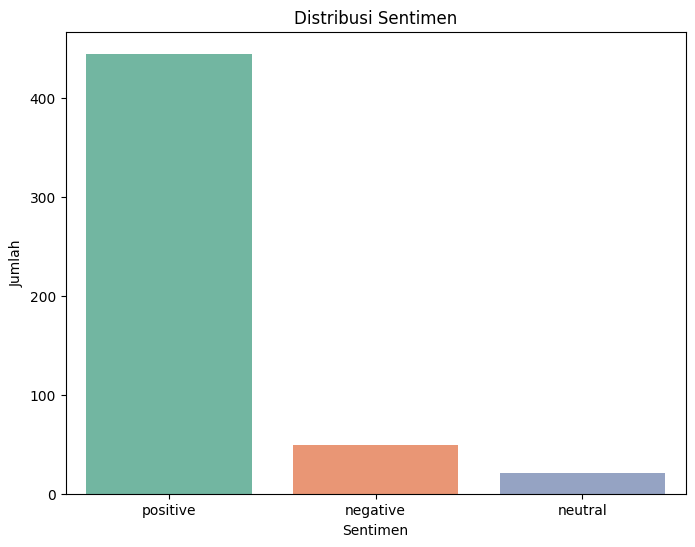

In [28]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='sentimen', palete='Set2')
plt.title('Distribusi Sentimen')
plt.xlabel('Sentimen')
plt.ylabel('Jumlah')
plt.show()

4. Training data

In [30]:
# Memastikan kolom sentimen diprediksi kembali jika hilang dari DataFrame
if 'sentimen' not in df.columns:
    df['sentimen'] = df['snippet'].apply(prediksi_sentimen)

x = df.snippet
y = df.sentimen

In [32]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42)

In [33]:
cvec=CountVectorizer()
tvec=TfidfVectorizer()
hvec=HashingVectorizer()

In [34]:
from sklearn.naive_bayes import MultinomialNB

clf = MultinomialNB()

In [35]:
model = Pipeline([('vectorizer',tvec)
                 ,('classifier',clf)])

In [36]:
model.fit(x_train,y_train)

Pipeline(steps=[('vectorizer', TfidfVectorizer()),
                ('classifier', MultinomialNB())])

In [37]:
hasil=model.predict(x_test)

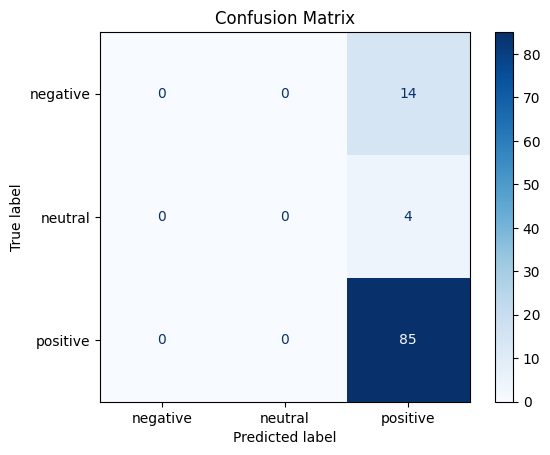

In [38]:
cm = confusion_matrix(y_test,hasil, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

In [39]:
matrix = classification_report(y_test,hasil)
print('Classification report : \n',matrix)

Classification report : 
               precision    recall  f1-score   support

    negative       0.00      0.00      0.00        14
     neutral       0.00      0.00      0.00         4
    positive       0.83      1.00      0.90        85

    accuracy                           0.83       103
   macro avg       0.28      0.33      0.30       103
weighted avg       0.68      0.83      0.75       103



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


5. Testing

In [41]:
def classify_text(input_text):
    return model_multinominalNaiveBayes.predict([input_text])[0]

model_multinominalNaiveBayes = model.fit(x_train, y_train)

In [43]:
input_text = input("Masukkan teks yang ingin diprediksi sentimennya: ")
predicted_sentiment = classify_text(input_text)

print("input kata :", input_text)
print("hasil sentimen :", predicted_sentiment)

Masukkan teks yang ingin diprediksi sentimennya: enak banget
input kata : enak banget
hasil sentimen : positive
